## 🐍 Python — Step 1: Dataset load

**Step 1: Import libraries**

**What I did:** Imported pandas, numpy and matplotlib.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'pandas'

**Step 2: Load the dataset**

**What I did:** Loaded the HHS CSV file into `df`.

In [ ]:
df=pd.read_csv(r"C:\Users\pintu\Downloads\HHS_Unaccompanied_Alien_Children_Program.csv")

**Step 3: Look at the first 10 rows**

**What I did:** Ran `df.head(10)` to understand the structure of the data.

**Result:** The Date column is stored as text (for example, December 21, 2025). The other 5 columns are numeric counts.

In [ ]:
df.head(10)

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,"December 21, 2025",6.0,18.0,11.0,"2,484",14.0
1,"December 18, 2025",11.0,50.0,6.0,"2,472",16.0
2,"December 17, 2025",7.0,31.0,11.0,"2,481",10.0
3,"December 16, 2025",8.0,54.0,15.0,"2,468",9.0
4,"December 15, 2025",11.0,42.0,9.0,"2,470",7.0
5,"December 14, 2025",8.0,35.0,4.0,"2,462",8.0
6,"December 11, 2025",7.0,47.0,9.0,"2,437",10.0
7,"December 10, 2025",10.0,54.0,5.0,"2,439",9.0
8,"December 09, 2025",4.0,30.0,7.0,"2,443",8.0
9,"December 08, 2025",9.0,27.0,9.0,"2,440",4.0


**Step 4: Check the shape**

**What I did:** Checked the number of rows and columns.

**Result:** 1170 rows and 6 columns.

In [ ]:
df.shape

(1170, 6)

**Step 5: Check column names**

**What I did:** Printed all column names.

**Result:** Date, Children apprehended and placed in CBP custody*, Children in CBP custody, Children transferred out of CBP custody, Children in HHS Care, Children discharged from HHS Care.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care'],
      dtype='str')

**Step 6: Check missing values**

**What I did:** Counted nulls in each column.

**Result:** 450 nulls in every column.

In [ ]:
df.isnull().sum()

Date                                               450
Children apprehended and placed in CBP custody*    450
Children in CBP custody                            450
Children transferred out of CBP custody            450
Children in HHS Care                               450
Children discharged from HHS Care                  450
dtype: int64

**Step 7: Count fully empty rows**

**What I did:** Selected rows where every column is null.

**Result:** 450 rows are completely empty.

In [ ]:
df[df.isnull().all(axis=1)].shape

(450, 6)

**Step 8: Remove empty rows**

**What I did:** Removed the fully empty rows with `dropna(how="all")`.

In [ ]:
df=df.dropna(how="all")

**Step 9: Recheck the shape**

**What I did:** Checked the shape after removing the empty rows.

**Result:** 720 rows and 6 columns.

In [ ]:
df.shape

(720, 6)

**Step 10: Check for duplicates**

**What I did:** Ran `df.duplicated()`.

**Result:** The visible output shows all False. I did not calculate the total count with `.sum()`.

In [ ]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
715    False
716    False
717    False
718    False
719    False
Length: 720, dtype: bool

## Date column check

**Step 11: Check the Date data type**

**What I did:** Checked the data type of the `Date` column.

**Result:** Date is stored as a string.

In [ ]:
df["Date"].dtype

<StringDtype(storage='python', na_value=nan)>

**Step 12: Convert Date to datetime**

**What I did:** Converted `Date` to datetime with `pd.to_datetime`.

In [ ]:
df["Date"]=pd.to_datetime(df["Date"])

**Step 13: Verify the Date conversion**

**What I did:** Checked the data type again after conversion.

**Result:** The type is `datetime64`, so the conversion worked.

In [ ]:
df["Date"].dtype

dtype('<M8[us]')

**Step 14: Recheck nulls**

**What I did:** Checked for nulls after the date conversion.

**Result:** 0 nulls in every column.

In [ ]:
df.isnull().sum()

Date                                               0
Children apprehended and placed in CBP custody*    0
Children in CBP custody                            0
Children transferred out of CBP custody            0
Children in HHS Care                               0
Children discharged from HHS Care                  0
dtype: int64

**Step 15: Run df.info()**

**What I did:** Checked non-null counts and data types.

**Result:** Every column has 720 non-null values. `Children in HHS Care` is still text. The other columns are float or datetime.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 6 columns):
 #   Column                                           Non-Null Count  Dtype         
---  ------                                           --------------  -----         
 0   Date                                             720 non-null    datetime64[us]
 1   Children apprehended and placed in CBP custody*  720 non-null    float64       
 2   Children in CBP custody                          720 non-null    float64       
 3   Children transferred out of CBP custody          720 non-null    float64       
 4   Children in HHS Care                             720 non-null    str           
 5   Children discharged from HHS Care                720 non-null    float64       
dtypes: datetime64[us](1), float64(4), str(1)
memory usage: 33.9 KB


**Step 16: Inspect HHS Care values**

**What I did:** Looked at the `Children in HHS Care` column directly.

**Result:** The values are text with commas, for example "2,484".

In [ ]:
df["Children in HHS Care"]

0      2,484
1      2,472
2      2,481
3      2,468
4      2,470
       ...  
715    7,538
716    7,433
717    7,280
718    7,122
719    6,566
Name: Children in HHS Care, Length: 720, dtype: str

**Step 17: Remove commas**

**What I did:** Removed the commas with `str.replace(",", "")`.

In [ ]:
df["Children in HHS Care"]= df["Children in HHS Care"].str.replace(",","")

**Step 18: Convert to numeric**

**What I did:** Converted the column to numbers with `pd.to_numeric`.

In [ ]:
df["Children in HHS Care"]=pd.to_numeric(df["Children in HHS Care"])

**Step 19: Verify the HHS Care data type**

**What I did:** Checked the data type after conversion.

**Result:** The type is `int64`.

In [ ]:
df['Children in HHS Care'].dtype

dtype('int64')

**Step 20: Check for negative values**

**What I did:** Looked for values below 0 in the apprehended column.

**Result:** No rows found, so there are no negative values.

In [ ]:
df[df["Children apprehended and placed in CBP custody*"] < 0 ]

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care


**Step 21: Check for decimal values**

**What I did:** Looked for decimal values in the transfers column.

**Result:** No rows found, so all values are whole numbers.

In [ ]:
df[ df["Children transferred out of CBP custody"] % 1 != 0 ]

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care


## EDA (Exploratory Data Analysis)

**Step 22: Find the date range**

**What I did:** Found the earliest and latest dates.

**Result:** 12 Jan 2023 to 21 Dec 2025.

In [ ]:
max_date = df["Date"].max()
min_date=df["Date"].min()


print("Max_date:",max_date)
print("Min_date:",min_date)

Max_date: 2025-12-21 00:00:00
Min_date: 2023-01-12 00:00:00


**Step 23: Create a Year column**

**What I did:** Created a `Year` column from `Date`.

In [ ]:
df['Year']=df["Date"].dt.year

**Step 24: Count Year values**

**What I did:** Counted the non-null values in `Year`.

**Result:** 720.

In [ ]:
df["Year"].count()

np.int64(720)

**Step 25: Count rows per year**

**What I did:** Counted the rows for each year.

**Result:** 2024 has 251, 2025 has 239 and 2023 has 230.

In [ ]:
df["Year"].value_counts()

Year
2024    251
2025    239
2023    230
Name: count, dtype: int64

**Step 26: Create a Month name column**

**What I did:** Extracted the month name from `Date`.

In [ ]:
df["Month"]=df["Date"].dt.month_name()

**Step 27: Shorten the month names**

**What I did:** Changed the month to a 3-letter form (Jan, Feb). This overwrote the previous `Month` column.

In [ ]:
df["Month"]=df["Date"].dt.strftime("%b") 

**Step 28: View the table**

**What I did:** Displayed `df` after adding `Year` and `Month`.

**Result:** 720 rows.

In [ ]:
df 

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Year,Month
0,2025-12-21,6.0,18.0,11.0,2484,14.0,2025,Dec
1,2025-12-18,11.0,50.0,6.0,2472,16.0,2025,Dec
2,2025-12-17,7.0,31.0,11.0,2481,10.0,2025,Dec
3,2025-12-16,8.0,54.0,15.0,2468,9.0,2025,Dec
4,2025-12-15,11.0,42.0,9.0,2470,7.0,2025,Dec
...,...,...,...,...,...,...,...,...
715,2023-01-25,20.0,22.0,41.0,7538,180.0,2023,Jan
716,2023-01-24,47.0,42.0,47.0,7433,175.0,2023,Jan
717,2023-01-23,32.0,50.0,39.0,7280,181.0,2023,Jan
718,2023-01-22,32.0,49.0,39.0,7122,227.0,2023,Jan


**Step 29: Count rows per month**

**What I did:** Counted the rows for each month.

**Result:** April has the most (66) and January has the fewest (52).

In [ ]:
df['Month'].value_counts()

Month
Apr    66
Oct    64
Sep    63
Jul    63
Mar    62
May    61
Aug    59
Nov    58
Jun    58
Feb    58
Dec    56
Jan    52
Name: count, dtype: int64

**Step 30: Run describe()**

**What I did:** Calculated summary statistics for the numeric columns.

**Result:** Apprehended: mean 93.5, max 333. CBP custody: mean 171.5, max 531. Transfers: mean 128.7, max 440.

In [ ]:
df.describe()

,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care,Year
count,720,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000
mean,2024-07-06 05:30:00,93.523611,171.494444,128.668056,6061.275000,173.406944,2024.012500
min,2023-01-12 00:00:00,0.000000,7.000000,0.000000,1972.000000,0.000000,2023.000000
25%,2023-10-16 18:00:00,12.000000,36.000000,14.000000,2467.750000,19.750000,2023.000000
50%,2024-07-05 12:00:00,99.000000,193.000000,157.000000,6406.500000,181.000000,2024.000000
75%,2025-03-25 06:00:00,147.250000,263.250000,199.250000,8010.250000,267.000000,2025.000000
max,2025-12-21 00:00:00,333.000000,531.000000,440.000000,11516.000000,505.000000,2025.000000
std,NaN,72.646625,126.354965,97.322012,2833.070109,125.702841,0.807551


**Step 31: Check date gaps**

**What I did:** Calculated the difference between consecutive sorted dates.

In [ ]:
df["Date"].sort_values().diff()

719       NaT
718   10 days
717    1 days
716    1 days
715    1 days
        ...  
4      1 days
3      1 days
2      1 days
1      1 days
0      3 days
Name: Date, Length: 720, dtype: timedelta64[us]

**Step 32: Count the gaps**

**What I did:** Counted how often each gap occurs.

**Result:** 558 gaps of 1 day, 122 of 3 days, 23 of 4 days and 10 of 2 days. The largest gap is 10 days. The data is not recorded every day.

In [ ]:
df["Date"].sort_values().diff().value_counts()

Date
1 days     558
3 days     122
4 days      23
2 days      10
5 days       3
10 days      1
6 days       1
7 days       1
Name: count, dtype: int64

**Step 33: Create a Year_Month column**

**What I did:** Created a monthly period column from `Date`.

In [ ]:
df["Year_Month"] = df["Date"].dt.to_period("M")

**Step 34: Build the monthly average table**

**What I did:** Calculated the mean of the 5 columns for each `Year_Month`.

In [ ]:
monthly = df.groupby("Year_Month")[
    [
        "Children apprehended and placed in CBP custody*",
        "Children in CBP custody",
        "Children transferred out of CBP custody",
        "Children in HHS Care",
        "Children discharged from HHS Care"
    ]
].mean().reset_index()

**Step 35: View the monthly table**

**What I did:** Ran `monthly.head()`.

**Result:** Jan 2023 monthly averages: apprehended 30.9, CBP custody 43.9, HHS Care 7,369.6.

In [ ]:
monthly.head()

,Year_Month,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01,30.875000,43.875000,34.500000,7369.625000,232.000000
1,2023-02,99.263158,171.315789,138.789474,7795.789474,272.789474
2,2023-03,130.473684,245.105263,178.894737,7945.368421,282.894737
3,2023-04,149.000000,250.190476,188.904762,7842.666667,269.904762
4,2023-05,124.818182,216.954545,164.636364,8187.136364,284.363636


**Step 36: Check the monthly shape**

**What I did:** Checked the shape of the monthly table.

**Result:** 36 rows and 6 columns, one row per month.

In [ ]:
monthly.shape

(36, 6)

**Step 37: Recheck column names**

**What I did:** Checked the column names before building the charts.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care', 'Year',
       'Month', 'Year_Month'],
      dtype='str')

**Step 38: Chart 1: HHS care load**

**What I did:** Plotted the monthly average HHS care as a line chart. Question: when did the HHS care load rise and fall?

**Result:** About 7,400 in Jan 2023. It peaked near 11,000 around Dec 2023. It dropped to about 6,000 during 2024. It fell sharply in Jan to Feb 2025 and stayed flat at 2,000 to 2,500.

In [ ]:
# 📊 Chart 1 — HHS Care Load Trend
# QUESTION = When did the HHS care load increase, and when did it decrease?
# Purpose: To determine the average number of  children in HHS care and analyze how the care loadchanged over time.

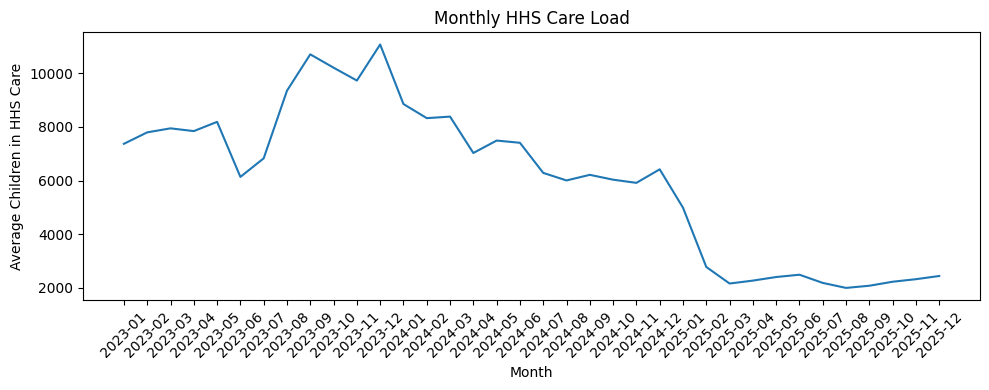

In [ ]:
HHS_Care_Load_Trend = df.groupby("Year_Month")["Children in HHS Care"].mean()

x = HHS_Care_Load_Trend.index.astype(str)
y = HHS_Care_Load_Trend.values

plt.figure(figsize=(10,4))
plt.plot(x, y)

plt.title("Monthly HHS Care Load")
plt.xlabel("Month")
plt.ylabel("Average Children in HHS Care")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Step 39: Recheck column names**

**What I did:** Checked the column names before the next chart.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care', 'Year',
       'Month', 'Year_Month'],
      dtype='str')

**Step 40: Chart 2: CBP custody**

**What I did:** Plotted the monthly average CBP custody as a line chart. Question: when was the pressure on the CBP system highest?

**Result:** Peak near 440 in Jan 2024. It stayed between 200 and 340 through 2024. After Dec 2024 it fell suddenly to 20 to 35 and stayed there.

In [ ]:
# 📊 Chart 2 — CBP Custody Tren

# Question:

# When was the pressure on the CBP system at its highest?
# Purpose: To analyze the monthly average number of children in CBP custody.

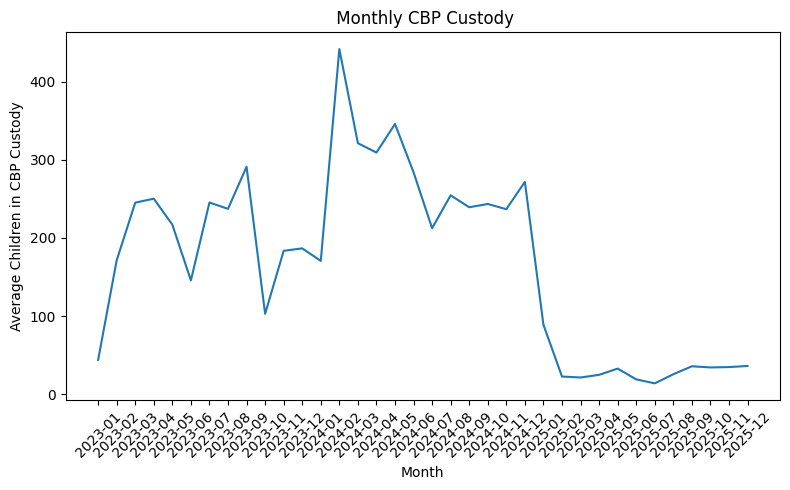

In [ ]:
CBP_Custody_Trend = df.groupby("Year_Month")["Children in CBP custody"].mean()

x = CBP_Custody_Trend.index.astype(str)
y = CBP_Custody_Trend.values

plt.figure(figsize=(8,5))
plt.plot(x,y)

plt.title(" Monthly CBP Custody")
plt.xlabel("Month")
plt.ylabel("Average Children in CBP Custody")


plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Step 41: Recheck column names**

**What I did:** Checked the column names before the next chart.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care', 'Year',
       'Month', 'Year_Month'],
      dtype='str')

**Step 42: Chart 3: Apprehensions**

**What I did:** Plotted the monthly average apprehensions as a line chart. Question: when did the incoming workload rise?

**Result:** Peak around 225 in Jan 2024. It stayed between 120 and 165 through 2024. After Dec 2024 it fell below 10.

In [ ]:
# 📊 Chart 3 — Children Apprehended Trend
#  QUESTION:  When did the incoming workload increase?

# Purpose: To analyze the pattern of incoming children into the system.

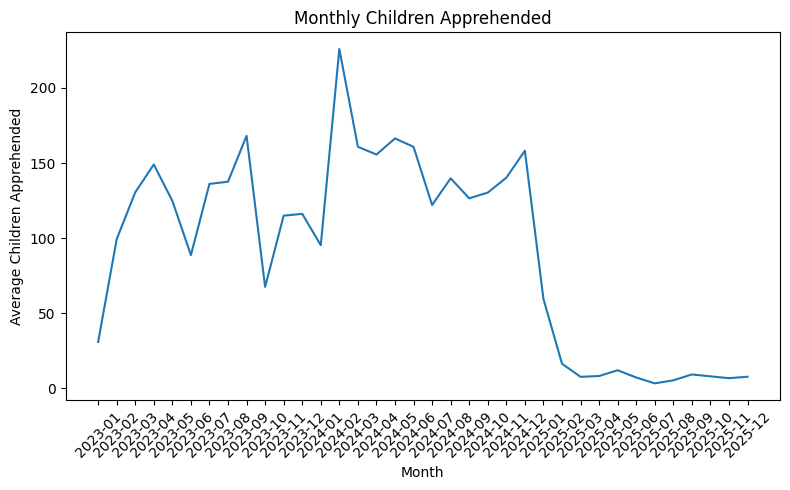

In [ ]:
Children_Apprehended_Trend = df.groupby("Year_Month")["Children apprehended and placed in CBP custody*"].mean()

x = Children_Apprehended_Trend.index.astype(str)
y = Children_Apprehended_Trend.values

plt.figure(figsize=(8,5))
plt.plot(x,y)



plt.title("Monthly Children Apprehended")
plt.xlabel("Month")
plt.ylabel("Average Children Apprehended")


plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

**Step 43: Recheck column names**

**What I did:** Checked the column names before the next chart.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care', 'Year',
       'Month', 'Year_Month'],
      dtype='str')

**Step 44: Chart 4: Transfers vs HHS discharges**

**What I did:** Plotted the monthly averages of both measures on one chart.

**Result:** In 2023 discharges were higher (200 to 350) than transfers (90 to 210). In Jan to Mar 2024 transfers overtook discharges, peaking near 315. From mid 2024 to Jan 2025 both stayed between 150 and 200. After Feb 2025 both fell below 20.

In [ ]:
# Chart 4 — Transfers vs HHS Discharges
# How did children leaving CBP custody compare with children discharged from HHS Care over time?
# Purpose: To compare the monthly average number of children transferred out of CBP custody with the number discharged from HHS care.

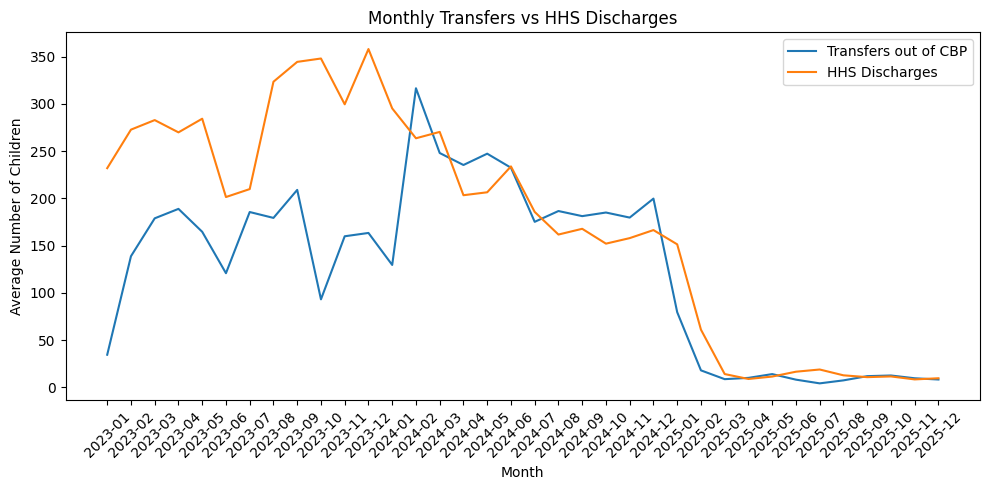

In [ ]:
Transfers_Discharge_Trend = df.groupby("Year_Month")[
    ["Children transferred out of CBP custody",
     "Children discharged from HHS Care"]
].mean()

x = Transfers_Discharge_Trend.index.astype(str)

y1 = Transfers_Discharge_Trend["Children transferred out of CBP custody"]
y2 = Transfers_Discharge_Trend["Children discharged from HHS Care"]

plt.figure(figsize=(10,5))

plt.plot(x, y1, label="Transfers out of CBP")
plt.plot(x, y2, label="HHS Discharges")

plt.title("Monthly Transfers vs HHS Discharges")
plt.xlabel("Month")
plt.ylabel("Average Number of Children")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()


**Step 45: Recheck column names**

**What I did:** Checked the column names before the next chart.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care', 'Year',
       'Month', 'Year_Month'],
      dtype='str')

**Step 46: Chart 5: Apprehensions vs transfers**

**What I did:** Plotted incoming children and transfers out on one chart.

**Result:** Transfers stayed above apprehensions in most months. Both lines follow the same pattern. After Jan 2025 both dropped to 5 to 10 and became almost equal.

In [ ]:
# 📊 Chart 5 — Apprehensions vs Transfers

# Question:

# How did the number of incoming children compare with the number of children transferred out of CBP custody over time?

# Purpose:

# To compare the incoming workload with the outgoing flow of children from CBP custody over time.

# Apprehensions = Incoming children into the system
# Transfers = Children transferred out of CBP custody

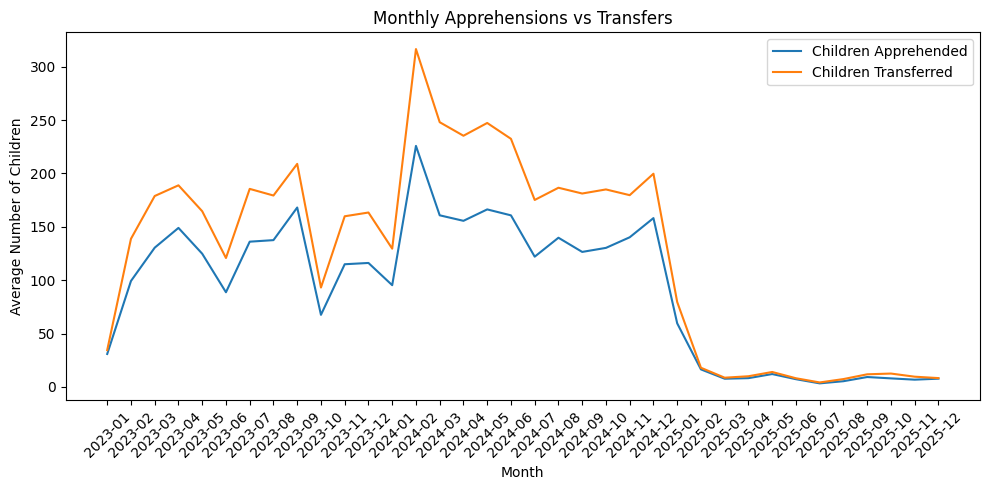

In [ ]:
Apprehended_Transfer_Trend = df.groupby("Year_Month")[
    ["Children apprehended and placed in CBP custody*",
     "Children transferred out of CBP custody"]
].mean()

x = Apprehended_Transfer_Trend.index.astype(str)

y1 = Apprehended_Transfer_Trend[
    "Children apprehended and placed in CBP custody*"
]

y2 = Apprehended_Transfer_Trend[
    "Children transferred out of CBP custody"
]

plt.figure(figsize=(10,5))

plt.plot(x, y1, label="Children Apprehended")
plt.plot(x, y2, label="Children Transferred")

plt.title("Monthly Apprehensions vs Transfers")
plt.xlabel("Month")
plt.ylabel("Average Number of Children")

plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()

**Step 47: Recheck column names**

**What I did:** Checked the column names before the next chart.

In [ ]:
df.columns

Index(['Date', 'Children apprehended and placed in CBP custody*',
       'Children in CBP custody', 'Children transferred out of CBP custody',
       'Children in HHS Care', 'Children discharged from HHS Care', 'Year',
       'Month', 'Year_Month'],
      dtype='str')

**Step 48: Chart 6: CBP custody vs HHS care**

**What I did:** Plotted a scatter chart of daily observations (x = CBP custody, y = HHS care).

**Result:** Two separate clusters appear. In one, CBP custody is below 60 and HHS care is 2,000 to 2,500. In the other, CBP custody is 100 to 500 and HHS care is 4,500 to 11,500. Above 100, a higher CBP custody does not show a clear linear rise in HHS care. I did not calculate a correlation.

In [ ]:

#📊 Chart 6 — CBP Custody vs HHS Care
# Question

# Is higher CBP custody associated with a higher HHS care load?

# Purpose

# To visually examine the relationship and correlation between CBP custody and HHS care load.

# X-axis: Children in CBP custody
# Y-axis: Children in HHS Care
# Chart: Scatter plot
# Each dot: Represents one daily observation

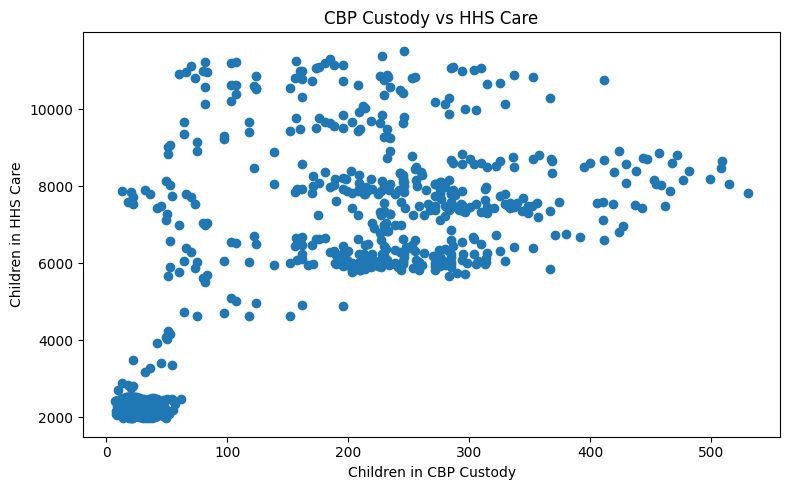

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Children in CBP custody"],
    df["Children in HHS Care"]
)

plt.title("CBP Custody vs HHS Care")
plt.xlabel("Children in CBP Custody")
plt.ylabel("Children in HHS Care")

plt.tight_layout()
plt.show()

**Step 49: Save the cleaned data**

**What I did:** Exported the cleaned `df` to `UAC_Cleaned_Data.csv` without the index.

In [ ]:
df.to_csv("UAC_Cleaned_Data.csv", index=False)

NameError: name 'df' is not defined